$$\textbf{REGLA COMPUESTA DE SIMPSON}$$


Para la integración numérica habitual, por Teorema Fundamental del Calculo, sabemos que basta solo con encontrar la antiderivada
de una función para luego evaluar sobre el intervalo dado y así hallar dicho resultado, siempre y cuando tenga una antiderivada elemental. Por desgracia, cuando la función $f(x)$ no tiene una antiderivada elemental, por ejemplo
            $$e^{x^2}$$          $$\frac{\sin(x)}{x}$$          $$x!$$
es donde no podemos hallar un resultado exacto, pero si podemos recurrir a técnicas que nos ayuden a aproximar al menos (con cierto grado de error) a un resultado considerablemente óptimo. Existen diversas reglas de recurrencia para poder aproximar este tipo de integrales difíciles, una de ellas (con una aproximación buena) es la regla de Simpson:

$$\int_{x_0}^{x_2} f(x)\,dx=\frac{h}{3}[f(x_0)+4f(x_1)+f(x_2)]-\frac{h^5}{90}f^{IV}(\xi);  x_0=a, x_2=b, x_1=\frac{a+b}{2}, \xi\in[x_0,x_2]$$

La regla por si sola es buena, pero cuando se trata de integrales más laboriosas como
                                                    $$\int_{-1}^{3}e^{3x}\cos(5x)\,dx$$
y que se requiera una presición de al menos 5 decimas es imposible, simplemente porque el grado de exactitud de la regla es bajo en relación a la exactitud que se requiere. Es por eso que se hace la extensión de esta regla, ¿cómo y para qué? bueno, supongamos que tenemos un intervalo en el cual se desea saber la integral numérica o el área bajo la curva de $f(x)$, llamemos al intervalo $[a,b]$, donde $a$ es el límite inferior y $b$ el límite superior del área a integrar sobre el eje $x$, luego $f$ tiene q ser una curva de clase $C^4$ continua bajo $[a,b]$; como estamos hablando que hay que aproximar la región integrada tomaremos rectángulos de base $h=\frac{b-a}{n}$ donde $n$ es el número entero positivo que indica en cuantos segmentos partiremos al intervalo antes dicho, y se generan los nuevos subintervalos en los puntos $x_j=a+jh$ para cada $j=0, 1, ..., n$. Se presume que existe una $\mu\in[a,b]$ tal que para el error en la nueva regla de Simpson se puede calcular de la siguiente forma:

$$\int_a^b f(x)\,dx=\frac{h}{3}[f(a)+2\sum_{j=1}^{\frac{n}{2}-1}f(x_{2j})+4\sum_{j=1}^{\frac{n}{2}}f(x_{2j-1})+f(b)]-\frac{b-a}{180}h^4f^{IV}(\mu)$$

Esta nueva regla nos asegura una mejor aproximación y sobre todo nos deja manipular de alguna manera la certeza del resultado de dicha integral, para acercarnos a ciertos decimales de exactitud.

El código base de este método tiene como propósito ser un objeto de ayuda para el cálculo de dicha integración numérica y evitar operaciones largas y recurrentes, esto para ahorrar tiempo y dar veracidad del resultado.



$$\textbf{Código para la regla compuesta de Simpson}$$


In [8]:
def s_c(f,a,b,n): #definimos nuestra función que hará el cálculo con la regla compyesta de Simpson
    h=(b-a)/n #se hace la partición de los subintervalos

    XI0=f(a)+f(b) #la suma de los extremos f(a) y f(b), los más fáciles
    XI1=0 #contador para la suma de f(x_2j-1)
    XI2=0 #contador para la suma de f(x_2j)

    for i in range(1,n): #se hace el bucle para identificar las sumas de x_j pares e impares
      X=a+i*h
      if i%2==0: #suma en el contador XI2 si x_j es par
        XI2=XI2+f(X)
      else: #suma en el contador XI1 si x_j es impar
        XI1=XI1+f(X)
          
    XI=h*(XI0+2*XI2+4*XI1)/3 #después de sumar en los contadores se hace la sua final de las XI0, XI1 y XI2

    return XI #devuelve el valor de la integral aproximada

Esto será la base para el cálculo de la siguiente integral de referencia

 $$\int_{0}^{2}e^{2x}\sin(3x)\,dx$$

Definiremos la función en el lenguaje correspondiente

$$\textbf{Ejemplo práctico.}$$


Calcular

 $$\int_{0}^{2}e^{2x}\sin(3x)\,dx$$

con la regla compuesta de Simpson con una presición de $10^{-4}$. Esto es, con una recursividad de $n=54$.

In [13]:
import numpy as np #librería para funciones matemáticas

def f(x): #definimos a f(x) como función matemática
    return np.exp(2*x)*np.sin(3*x) #devuelve el cálculo de la funcion e^(2x)·sen(3x)

I=s_c(f,0,2,54) #se usa la función creada anteriormente para la regla de Simpson compuesta con los valores de nuestro problema ejemplo

print(I) #imprime el resultado, solo como prueba de funcionalidad del código

-14.213964900134542


El hecho que se pida la integral con presición de $10^{-4}$ quiere decir que se pide el resultado con al menos 4 dédimas de presición, lo cual es verdadero (se puede comprobar con alguna aplicación graficadora como GeoGebra). Para un mejor entendimiento de lo que ha calculado este código se hace una referencia gráfica del área calculada.

$$\textbf{Gráfica de f(x)}$$

Text(0.5, 200, 'I= -14.213964900134542')

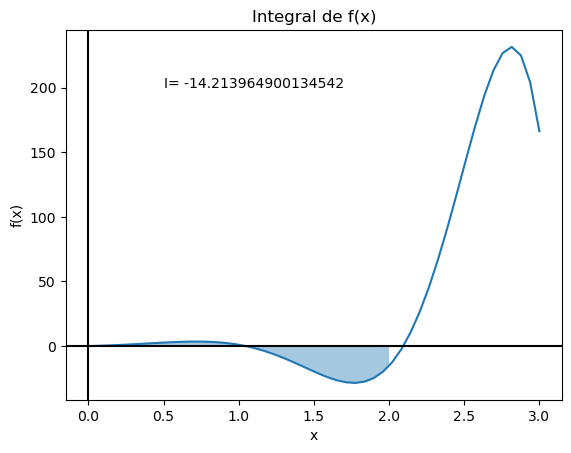

In [37]:
import matplotlib.pyplot as plt #librería para la generación de gráficas

x=np.linspace(0,3) #genera una reticula o una partición
plt.plot(x,f(x)) #dibuja la gráfica de y=f(x)
plt.xlabel('x') #un pequeño letrero que indica los valores de x
plt.ylabel('f(x)') #un pequeño letrero que indica los valores de f(x)
plt.title('Integral de f(x)') #Encabezado de la gráfica
plt.axhline(y=0, color = 'black') #pinta un eje X
plt.axvline(x=0, color = 'black') #pinta un eje Y
a_I=np.linspace(0,2) #es importante esto, funciona como indicador para el área que se quiere sombrear de la integral
plt.fill_between(a_I, f(a_I), 0, alpha=0.4) #colorea el area bajo la curva de f(x) de 0 a 2
plt.text(0.5, 200, f"I= {I}") #aprovechamos la memoria guardada del resultado de I y hacemos incapié al resultado obtenido de la integral en la gráfica

En la imagen se muestra la integral de la curva $f(x)=e^{2x}\sin(3x)$ en el intervalo $[0,2]$. Es así como funciona el método de la regla compuesta se Simpson, como se puede ver, si modificamos parámetros podemos tener una aproximación más certera de $I$, sin necesidad de hacer cálculos a mano; he aquí la utilidad de este código. La gráfica nos ayuda a identificar y comprobar de manera visual el resultado. La integral da un número negativo ya que la mayor parte de la curva de $f(x)$ está debajo del eje $x$.

Finalmente, nuestra solución bajo las indicaciones dadas del problema es

$$I=\int_0^2 e^{2x}\sin(3x)\,dx \approx -14.213964$$
